<a href="https://colab.research.google.com/github/gcc712-lgtm/garbage-classification/blob/main/trash_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, kagglehub
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [2]:
path = kagglehub.dataset_download("mostafaabla/garbage-classification")
for root, dirs, files in os.walk(path):
    if len(dirs) == 12:
        data_dir = root
        break

Using Colab cache for faster access to the 'garbage-classification' dataset.


In [3]:
transform = transforms.Compose([transforms.Resize((128, 128)), transforms.ToTensor()])
dataset = datasets.ImageFolder(data_dir, transform=transform)
print(len(dataset.classes), dataset.classes)

idx = torch.randperm(len(dataset)).tolist()
n_tr, n_va = int(len(idx) * 0.7), int(len(idx) * 0.15)
tr_idx, va_idx, te_idx = idx[:n_tr], idx[n_tr:n_tr + n_va], idx[n_tr + n_va:]

12 ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']


과적합(Over Fitting)

In [4]:
# 과적합을 만들기 위해 학습 데이터는 2000장만 사용
small_train = Subset(dataset, tr_idx[:2000])

train_loader = DataLoader(small_train, batch_size=64, shuffle=True)
val_loader   = DataLoader(Subset(dataset, va_idx), batch_size=256, shuffle=False)
test_loader = DataLoader(Subset(dataset, te_idx), batch_size=256, shuffle=False)
print("학습:", len(small_train), "/검증:", len(va_idx))

학습: 2000 /검증: 2327


In [5]:
class PlainCNN(nn.Module):
    def __init__(self, n_classes=12):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 16 * 16, 256), nn.ReLU(),
            nn.Linear(256, n_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = PlainCNN().to(device)
print("파라미터:", f"{sum(p.numel() for p in model.parameters()):,}개")
print("학습 데이터:", len(small_train), "장")
print("→ 파라미터가 데이터보다 훨씬 많습니다")

파라미터: 4,253,964개
학습 데이터: 2000 장
→ 파라미터가 데이터보다 훨씬 많습니다


In [6]:
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

def measure(loader):
    model.eval()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += loss_fn(out, y).item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()
    return loss_sum / total, correct / total

history = []
for epoch in range(1, 31):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()

    tr = measure(train_loader)
    va = measure(val_loader)
    history.append((*tr, *va))

    if epoch % 5 == 0 or epoch == 1:
        print(f"epoch {epoch:2d}  학습 loss {tr[0]:.4f} acc {tr[1]:.4f}  |  "
              f"검증 loss {va[0]:.4f} acc {va[1]:.4f}")

epoch  1  학습 loss 1.8757 acc 0.3825  |  검증 loss 1.7842 acc 0.4095
epoch  5  학습 loss 0.9234 acc 0.6975  |  검증 loss 1.1574 acc 0.6197
epoch 10  학습 loss 0.3838 acc 0.8675  |  검증 loss 1.3434 acc 0.6403
epoch 15  학습 loss 0.0574 acc 0.9880  |  검증 loss 1.6551 acc 0.6622
epoch 20  학습 loss 0.0249 acc 0.9965  |  검증 loss 2.1927 acc 0.6554
epoch 25  학습 loss 0.0361 acc 0.9920  |  검증 loss 2.2587 acc 0.6502
epoch 30  학습 loss 0.0050 acc 0.9990  |  검증 loss 2.6399 acc 0.6678


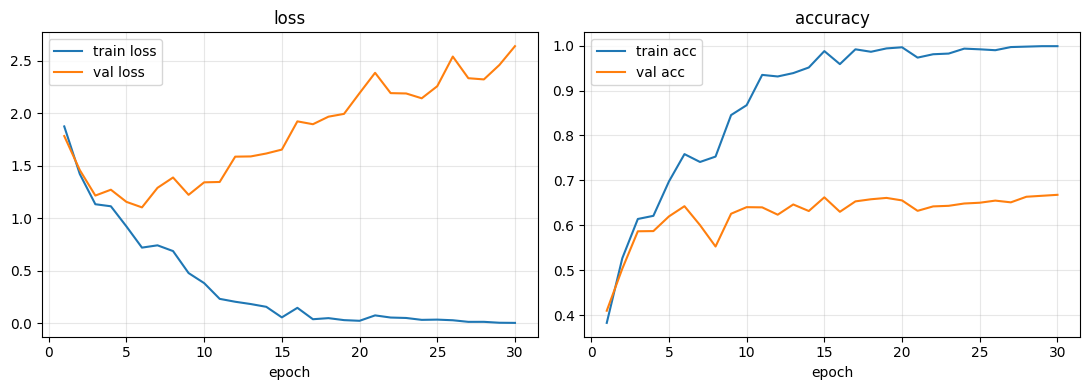

In [7]:
tr_l = [h[0] for h in history]; tr_a = [h[1] for h in history]
va_l = [h[2] for h in history]; va_a = [h[3] for h in history]
xs = range(1, len(history) + 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(xs, tr_l, label="train loss"); ax[0].plot(xs, va_l, label="val loss")
ax[0].set_title("loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(xs, tr_a, label="train acc"); ax[1].plot(xs, va_a, label="val acc")
ax[1].set_title("accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [8]:
best_epoch = int(torch.tensor(va_l).argmin()) + 1
print(f"검증 손실이 가장 낮았던 epoch: {best_epoch} (loss {min(va_l):.4f})")
print(f"마지막 epoch 검증 손실      : {va_l[-1]:.4f}")
print(f"→ {best_epoch} epoch 이후로는 학습을 계속해도 나빠졌습니다")

검증 손실이 가장 낮았던 epoch: 6 (loss 1.1048)
마지막 epoch 검증 손실      : 2.6399
→ 6 epoch 이후로는 학습을 계속해도 나빠졌습니다


In [9]:
import pandas as pd

gap = [a - b for a, b in zip(tr_a, va_a)]
df = pd.DataFrame({
    "epoch": list(xs),
    "학습 정확도": [round(v, 4) for v in tr_a],
    "검증 정확도": [round(v, 4) for v in va_a],
    "차이": [round(v, 4) for v in gap],
})
print(df.iloc[[0, 4, 9, 14, 19, 24, 29]].to_string(index=False))
print(f"\n최종 차이: {gap[-1]:.4f}")
print("→ 0.10 이상이면 과적합이 뚜렷합니다" if gap[-1] > 0.10 else "→ 아직 심하지 않습니다")

 epoch  학습 정확도  검증 정확도      차이
     1  0.3825  0.4095 -0.0270
     5  0.6975  0.6197  0.0778
    10  0.8675  0.6403  0.2272
    15  0.9880  0.6622  0.3258
    20  0.9965  0.6554  0.3411
    25  0.9920  0.6502  0.3418
    30  0.9990  0.6678  0.3312

최종 차이: 0.3312
→ 0.10 이상이면 과적합이 뚜렷합니다


In [10]:
big_loader = DataLoader(Subset(dataset, tr_idx), batch_size=64, shuffle=True)

model2 = PlainCNN().to(device)
opt2 = torch.optim.Adam(model2.parameters(), lr=1e-3)

for epoch in range(10):
    model2.train()
    for x, y in big_loader:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model2(x), y)
        opt2.zero_grad(); loss.backward(); opt2.step()

model_backup = model
model = model2
tr2, va2 = measure(big_loader), measure(val_loader)
model = model_backup

print(f"2,000장  최종 차이: {gap[-1]:.4f}")
print(f"{len(tr_idx):,}장 최종 차이: {tr2[1] - va2[1]:.4f}")

2,000장  최종 차이: 0.3312
10,860장 최종 차이: 0.2167


데이터 증강

In [11]:
from torch.utils.data import Dataset

X = torch.stack([dataset[i][0] for i in range(len(dataset))])
Y = torch.tensor(dataset.targets)

class DS(Dataset):
    def __init__(self, ids, tf=None):
        self.ids, self.tf = ids, tf
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        x = X[self.ids[i]]
        if self.tf:
            x = self.tf(x)
        return x, Y[self.ids[i]]

def make_loader(ids, tf=None, bs=64, shuffle=False):
    return DataLoader(DS(ids, tf), batch_size=bs, shuffle=shuffle)

small_idx = tr_idx[:2000]
val_loader   = make_loader(va_idx, bs=256)
test_loader  = make_loader(te_idx, bs=256)
plain_loader = make_loader(small_idx, shuffle=True)
plain_eval   = make_loader(small_idx, bs=256)

In [12]:
class CNN(nn.Module):
    def __init__(self, n_classes=12, p=0.0, bn=False):
        super().__init__()
        def block(i, o):
            layers = [nn.Conv2d(i, o, 3, padding=1)]
            if bn: layers.append(nn.BatchNorm2d(o))
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            return layers
        self.features = nn.Sequential(*block(3, 32), *block(32, 64), *block(64, 64))
        fc = [nn.Flatten(), nn.Dropout(p), nn.Linear(64 * 16 * 16, 256)]
        if bn: fc.append(nn.BatchNorm1d(256))
        fc += [nn.ReLU(), nn.Dropout(p), nn.Linear(256, n_classes)]
        self.classifier = nn.Sequential(*fc)
    def forward(self, x):
        return self.classifier(self.features(x))

def evaluate(m, loader):
    m.eval()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = m(x)
            loss_sum += loss_fn(out, y).item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()
    return loss_sum / total, correct / total

def fit(m, loader, plain, epochs=30, lr=1e-3, quiet=False):
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    hist = []
    for epoch in range(1, epochs + 1):
        m.train()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(m(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
        tr = evaluate(m, plain)
        va = evaluate(m, val_loader)
        hist.append((*tr, *va))
        if not quiet and (epoch % 10 == 0 or epoch == 1):
            print(f"epoch {epoch:2d}  학습 loss {tr[0]:.4f} acc {tr[1]:.4f}  |  "
                  f"검증 loss {va[0]:.4f} acc {va[1]:.4f}")
    return hist

def summary(name, h):
    return {"모델": name, "학습 정확도": round(h[-1][1], 4),
            "검증 정확도": round(h[-1][3], 4),
            "차이": round(h[-1][1] - h[-1][3], 4),
            "최고 검증": round(max(x[3] for x in h), 4)}

def compare(hists):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    for name, h in hists.items():
        ax[0].plot(range(1, len(h) + 1), [x[2] for x in h], label=name)
        ax[1].plot(range(1, len(h) + 1), [x[1] - x[3] for x in h], label=name)
    ax[0].set_title("val loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].set_title("train acc - val acc"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

def plot_history(h, title=""):
    tr_l, tr_a, va_l, va_a = zip(*h)
    xs = range(1, len(h) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    ax[0].plot(xs, tr_l, label="train loss"); ax[0].plot(xs, va_l, label="val loss")
    ax[0].set_title("loss " + title); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(xs, tr_a, label="train acc"); ax[1].plot(xs, va_a, label="val acc")
    ax[1].set_title("accuracy " + title); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

epoch  1  학습 loss 1.5428 acc 0.4670  |  검증 loss 1.5501 acc 0.4727
epoch 10  학습 loss 0.0234 acc 1.0000  |  검증 loss 1.0861 acc 0.6837
epoch 20  학습 loss 0.0014 acc 1.0000  |  검증 loss 1.1118 acc 0.6983
epoch 30  학습 loss 0.0006 acc 1.0000  |  검증 loss 1.1734 acc 0.6970
{'모델': 'BatchNorm only', '학습 정확도': 1.0, '검증 정확도': 0.697, '차이': 0.303, '최고 검증': 0.7082}


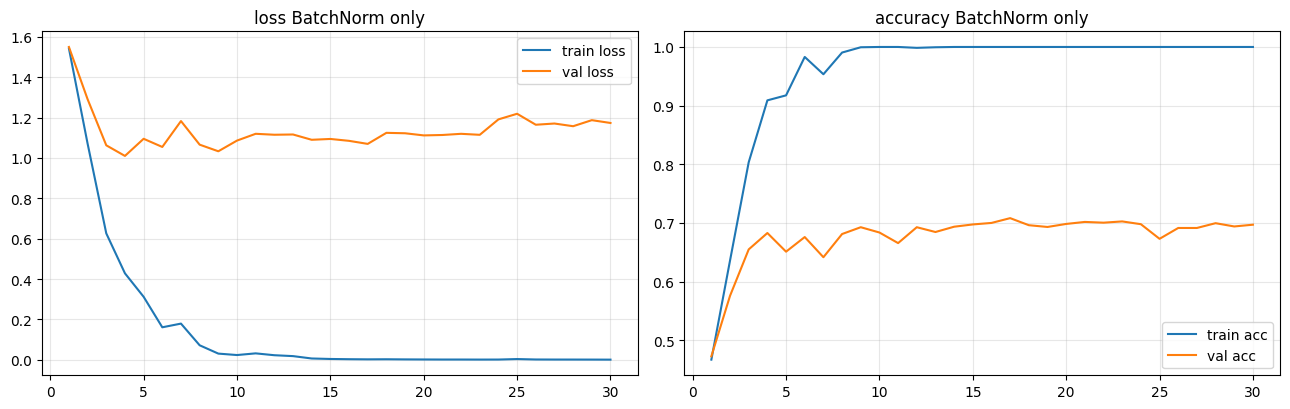

In [13]:
# BatchNorm 단독 적용 실험
torch.manual_seed(42)

bn_only = CNN(p=0.0, bn=True).to(device)

bn_hist = fit(
    bn_only,
    plain_loader,
    plain_eval,
    epochs=30,
    lr=1e-3
)

print(summary("BatchNorm only", bn_hist))
plot_history(bn_hist, "BatchNorm only")

epoch  1  학습 loss 1.7318 acc 0.4275  |  검증 loss 1.6776 acc 0.4418
epoch 10  학습 loss 0.4393 acc 0.8595  |  검증 loss 1.3638 acc 0.6180
epoch 20  학습 loss 0.0718 acc 0.9775  |  검증 loss 2.1526 acc 0.6369
epoch 30  학습 loss 0.0008 acc 1.0000  |  검증 loss 2.6696 acc 0.6657
epoch  1  학습 loss 1.8643 acc 0.3885  |  검증 loss 1.7990 acc 0.4104
epoch 10  학습 loss 0.9072 acc 0.6830  |  검증 loss 1.0681 acc 0.6425
epoch 20  학습 loss 0.5901 acc 0.8045  |  검증 loss 1.0593 acc 0.6725
epoch 30  학습 loss 0.3416 acc 0.8895  |  검증 loss 1.0705 acc 0.7043
          모델  학습 정확도  검증 정확도     차이  최고 검증
    baseline  1.0000  0.6657 0.3343 0.6713
augmentation  0.8895  0.7043 0.1852 0.7112


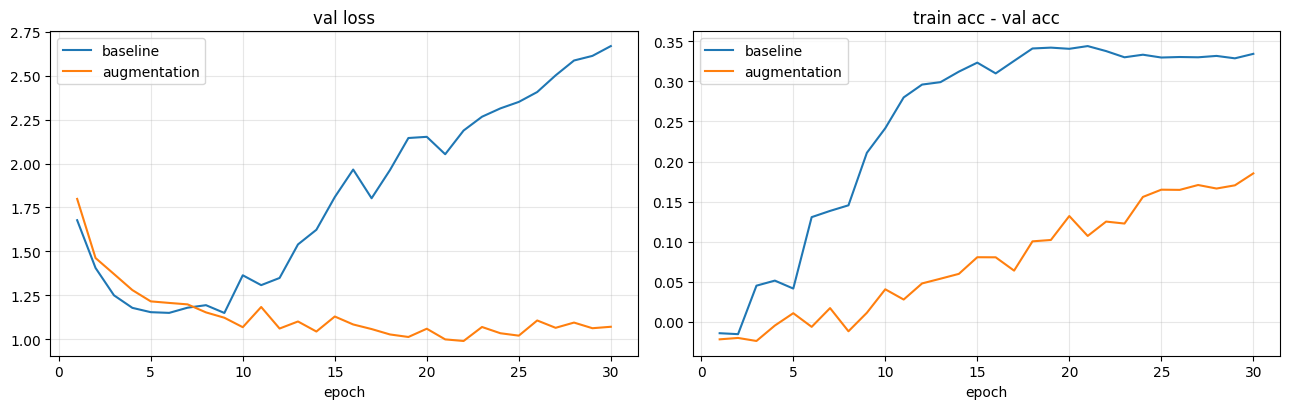

In [14]:
aug_tf = transforms.Compose([
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
])
aug_loader = make_loader(small_idx, aug_tf, shuffle=True)

torch.manual_seed(42); m1 = CNN().to(device); h1 = fit(m1, plain_loader, plain_eval)
torch.manual_seed(42); m2 = CNN().to(device); h2 = fit(m2, aug_loader, plain_eval)

print(pd.DataFrame([summary("baseline", h1), summary("augmentation", h2)]).to_string(index=False))
compare({"baseline": h1, "augmentation": h2})

In [15]:
rows = []
for deg in [0, 15, 30]:
    t = transforms.Compose([
        transforms.RandomRotation(deg),
        transforms.RandomHorizontalFlip(),
        transforms.RandomAffine(0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    ])
    loader = make_loader(small_idx, t, shuffle=True)
    torch.manual_seed(42); m = CNN().to(device)
    h = fit(m, loader, plain_eval, epochs=30, quiet=True)
    rows.append({"회전각": deg, "학습": round(h[-1][1], 4), "검증": round(h[-1][3], 4),
                 "차이": round(h[-1][1] - h[-1][3], 4)})
print(pd.DataFrame(rows).to_string(index=False))

 회전각     학습     검증     차이
   0 0.9185 0.7125 0.2060
  15 0.8950 0.7056 0.1894
  30 0.8460 0.6790 0.1670


  p  학습 정확도  검증 정확도     차이
0.0  1.0000  0.6652 0.3348
0.2  0.9975  0.6725 0.3250
0.5  0.9895  0.6957 0.2938
0.8  0.8035  0.6704 0.1331


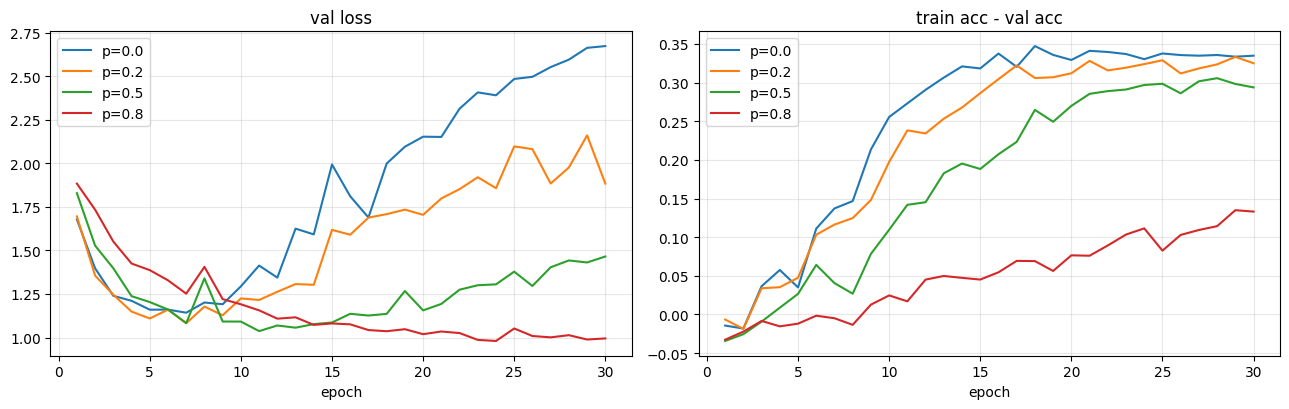

In [16]:
rows, drop_hists = [], {}
for p in [0.0, 0.2, 0.5, 0.8]:
    torch.manual_seed(42); m = CNN(p=p).to(device)
    h = fit(m, plain_loader, plain_eval, epochs=30, quiet=True)
    drop_hists[f"p={p}"] = h
    rows.append({"p": p, "학습 정확도": round(h[-1][1], 4), "검증 정확도": round(h[-1][3], 4),
                 "차이": round(h[-1][1] - h[-1][3], 4)})
print(pd.DataFrame(rows).to_string(index=False))
compare(drop_hists)

            모델  학습 정확도  검증 정확도     차이  최고 검증
      baseline  1.0000  0.6678 0.3322 0.6704
       bn only  1.0000  0.6682 0.3318 0.7022
           aug  0.8470  0.7069 0.1401 0.7069
   aug+dropout  0.7210  0.6657 0.0553 0.6764
        aug+bn  0.8590  0.7000 0.1590 0.7413
aug+dropout+bn  0.8205  0.7022 0.1183 0.7095


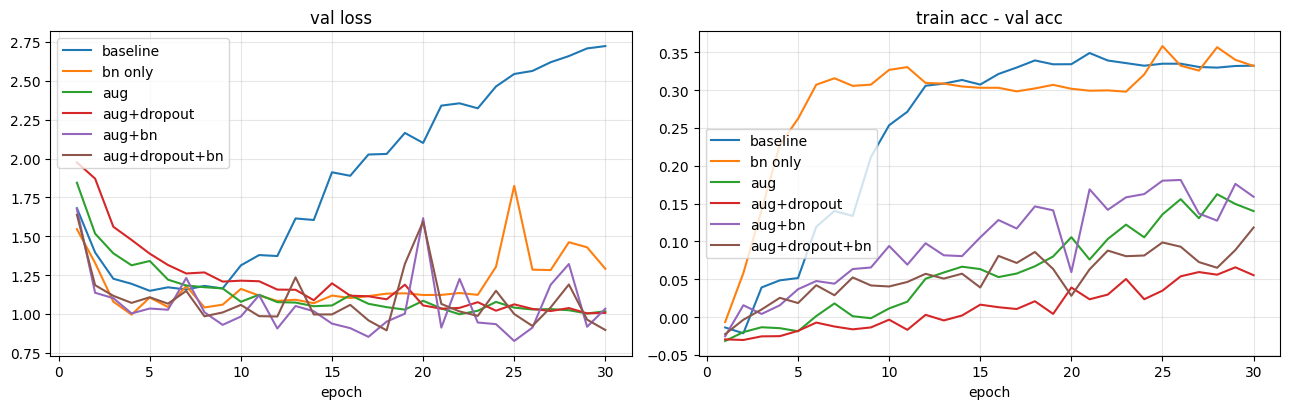

In [17]:
best_p, best_deg = 0.5, 30

tf_best = transforms.Compose([
    transforms.RandomRotation(best_deg),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
])
aug_best = make_loader(small_idx, tf_best, shuffle=True)

cases = {
    "baseline":       (dict(),                  plain_loader),
    "bn only":        (dict(bn=True),           plain_loader),
    "aug":            (dict(),                  aug_best),
    "aug+dropout":    (dict(p=best_p),          aug_best),
    "aug+bn":         (dict(bn=True),           aug_best),
    "aug+dropout+bn": (dict(p=best_p, bn=True), aug_best),
}
rows, combo_hists = [], {}
for name, (kw, loader) in cases.items():
    torch.manual_seed(42); m = CNN(**kw).to(device)
    h = fit(m, loader, plain_eval, epochs=30, quiet=True)
    combo_hists[name] = h
    rows.append(summary(name, h))
print(pd.DataFrame(rows).to_string(index=False))
compare(combo_hists)

In [18]:
rows = []
for lr in [1e-2, 1e-3, 1e-4]:
    for bs in [32, 64]:
        loader = make_loader(small_idx, tf_best, bs=bs, shuffle=True)
        torch.manual_seed(42); m = CNN(p=0, bn=True).to(device)
        h = fit(m, loader, plain_eval, epochs=30, lr=lr, quiet=True)
        rows.append({"lr": lr,
                     "batch": bs,
                     "학습 정확도": round(h[-1][1], 4),
                     "검증 정확도": round(h[-1][3], 4),
                     "차이": round(h[-1][1] - h[-1][3], 4),
                     "최고 검증": round(max(x[3] for x in h),4)})
print(pd.DataFrame(rows).to_string(index=False))

    lr  batch  학습 정확도  검증 정확도     차이  최고 검증
0.0100     32  0.5780  0.5256 0.0524 0.7082
0.0100     64  0.5835  0.5157 0.0678 0.6760
0.0010     32  0.8500  0.6927 0.1573 0.7370
0.0010     64  0.8100  0.6884 0.1216 0.7379
0.0001     32  0.9090  0.7512 0.1578 0.7512
0.0001     64  0.8890  0.7568 0.1322 0.7568


epoch  1  학습 loss 1.0102 acc 0.6751  |  검증 loss 1.0118 acc 0.6738
epoch 10  학습 loss 0.5569 acc 0.8216  |  검증 loss 0.6624 acc 0.7869
epoch 20  학습 loss 0.3981 acc 0.8771  |  검증 loss 0.5761 acc 0.8191
epoch 30  학습 loss 0.3090 acc 0.9079  |  검증 loss 0.5232 acc 0.8337


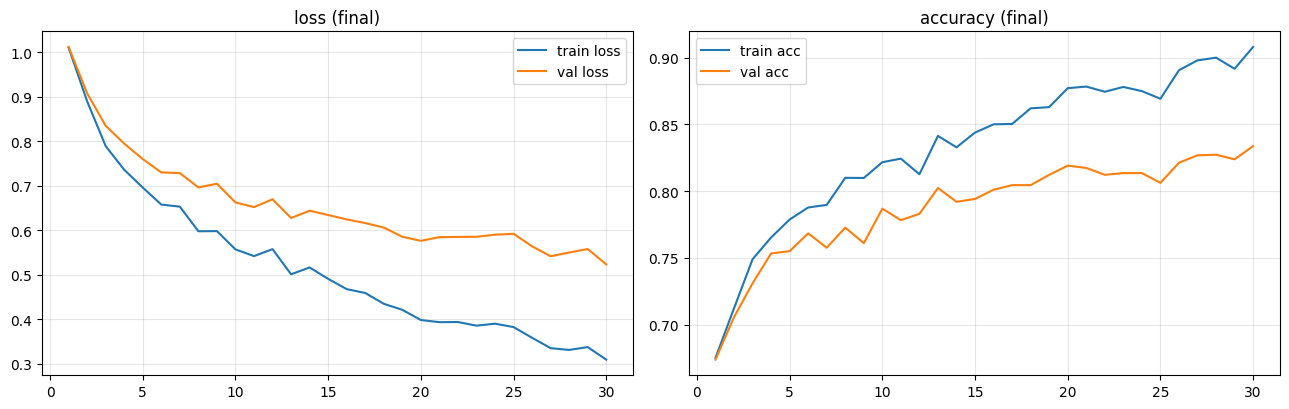

{'모델': 'final', '학습 정확도': 0.9079, '검증 정확도': 0.8337, '차이': 0.0742, '최고 검증': 0.8337}

테스트 loss 0.5297  acc 0.8303


In [19]:
best_lr, best_bs = 1e-4, 64

final_loader = make_loader(tr_idx, tf_best, bs=best_bs, shuffle=True)
full_eval    = make_loader(tr_idx, bs=256)

torch.manual_seed(42)
final = CNN(p=0, bn=True).to(device)
final_hist = fit(final, final_loader, full_eval, epochs=30, lr=best_lr)
plot_history(final_hist, "(final)")
print(summary("final", final_hist))

test_loss, test_acc = evaluate(final, test_loader)
print(f"\n테스트 loss {test_loss:.4f}  acc {test_acc:.4f}")

/tmp/ipykernel_390/1417669654.py:18: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_390/1417669654.py:18: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_390/1417669654.py:18: UserWarning: Glyph 54924 (\N{HANGUL SYLLABLE HOE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_390/1417669654.py:18: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_390/1417669654.py:18: UserWarning: Glyph 51340 (\N{HANGUL SYLLABLE JWA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_390/1417669654.py:18: UserWarning: Glyph 50864 (\N{HANGUL SYLLABLE U}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_390/1417669654.py:18: UserWarning: Glyph 48152 (\N{HANGUL SYLLABLE BAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()

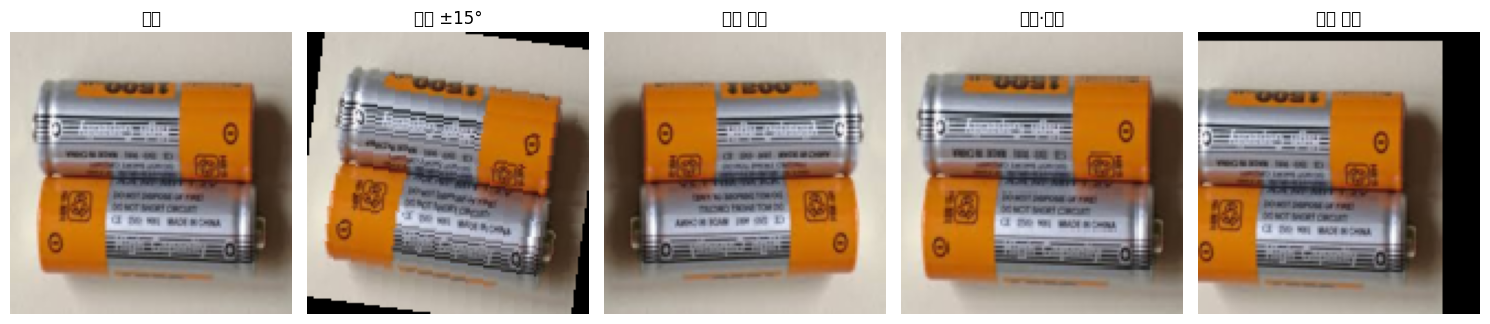

In [20]:
raw = datasets.ImageFolder(data_dir)
img, label = raw[0]

augs = {
    "원본":       transforms.Compose([transforms.Resize((128, 128)), transforms.ToTensor()]),
    "회전 ±15°":  transforms.Compose([transforms.Resize((128, 128)), transforms.RandomRotation(15), transforms.ToTensor()]),
    "좌우 반전":  transforms.Compose([transforms.Resize((128, 128)), transforms.RandomHorizontalFlip(p=1.0), transforms.ToTensor()]),
    "확대·축소":  transforms.Compose([transforms.Resize((128, 128)), transforms.RandomAffine(0, scale=(0.7, 1.3)), transforms.ToTensor()]),
    "위치 이동":  transforms.Compose([transforms.Resize((128, 128)), transforms.RandomAffine(0, translate=(0.2, 0.2)), transforms.ToTensor()]),
}

fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
for ax, (name, t) in zip(axes, augs.items()):
    tensor_img = t(img)
    ax.imshow(tensor_img.permute(1, 2, 0))
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

/tmp/ipykernel_390/1083843171.py:16: UserWarning: Glyph 44057 (\N{HANGUL SYLLABLE GAT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_390/1083843171.py:16: UserWarning: Glyph 51008 (\N{HANGUL SYLLABLE EUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_390/1083843171.py:16: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_390/1083843171.py:16: UserWarning: Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_390/1083843171.py:16: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_390/1083843171.py:16: UserWarning: Glyph 48264 (\N{HANGUL SYLLABLE BEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_390/1083843171.py:16: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


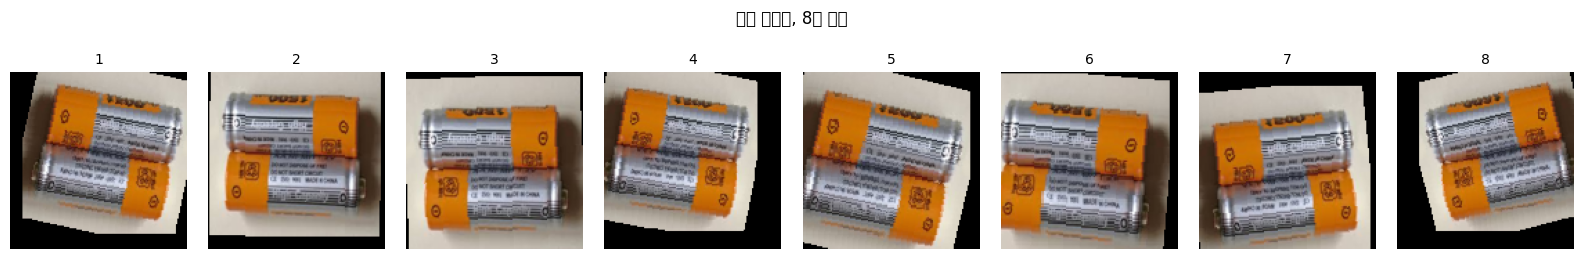

In [21]:
combo = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
])

fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for i, ax in enumerate(axes):
    tensor_img = combo(img)
    ax.imshow(tensor_img.permute(1, 2, 0))
    ax.set_title(f"{i+1}", fontsize=10)
    ax.axis("off")
plt.suptitle("같은 이미지, 8번 변형", y=1.06)
plt.tight_layout()
plt.show()